# 0.02 Reproduce Table 1 and Fig. 2

Gagnon et al., *Sci Data* 2026, doi 10.1038/s41597-025-06499-z. Run `make clean-survival` first.

In [1]:
import pandas as pd
from ucsd_pfs.config import PROCESSED_SURVIVAL, PROCESSED_TIMEPOINTS
from ucsd_pfs.reproduce import reproduce_fig2, reproduce_table1
from ucsd_pfs.survival import recompute_os
from ucsd_pfs.timeline import patient_timeline

tp = pd.read_parquet(PROCESSED_TIMEPOINTS)
surv = pd.read_parquet(PROCESSED_SURVIVAL)
surv.attrs["all_patients"] = recompute_os(patient_timeline(tp))

2026-10-28 12:13:19.403 | DEBUG    | ucsd_pfs.config:<module>:40 - PROJ_ROOT is /home/valentin/workspaces/ucsd


## Table 1

In [2]:
reproduce_table1(tp, surv)

total        survival_subset                                    \
            paper   ours           paper ours_provided_os ours_rule_cohort   
timepoints    243  243.0              94             85.0             96.0   
patients      178  178.0              94             85.0             96.0   
age_mean       56   55.7              58             57.8             57.2   
age_sd         13   13.4              13             13.0             13.0   
male          116  129.0              67             69.0             75.0   
female         62   49.0              27             16.0             21.0   
gtr            87   83.0              38             33.0             40.0   
mgmt_meth      76   76.0              17             19.0             26.0   
mgmt_unmeth    73   73.0              44             41.0             41.0   

                           
            v3_unrepaired  
timepoints           74.0  
patients             74.0  
age_mean             53.8  
age_sd               13.8  
male                 53.0  
female               21.0  
gtr                  40.0  
mgmt_meth            22.0  
mgmt_unmeth          19.0

## Fig. 2: KM OS by MGMT (paper: log-rank p = 0.00002)
The paper does not say which cohort or OS definition it used, so several variants are shown. Figures are in `reports/figures/`.

In [3]:
reproduce_fig2(tp, surv)

,variant,n,events,n_meth,n_unmeth,logrank_p,paper_p
0,provided_subset__v1_os,56,56,16,40,3.249764e-01,0.00002
1,v3_unrepaired__v3_os,39,39,22,17,3.574816e-01,0.00002
2,rule_cohort__clean_os,66,61,25,41,4.987062e-04,0.00002
3,rule_cohort__recomputed_os,56,51,22,34,1.267663e-04,0.00002
4,all_patients__recomputed_os,91,77,47,44,2.731121e-07,0.00002


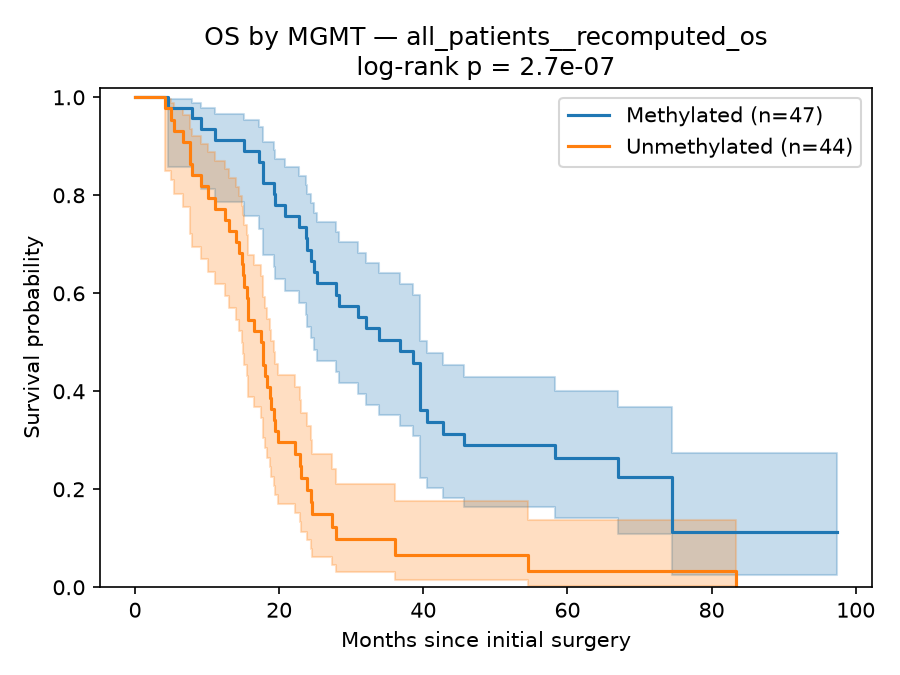

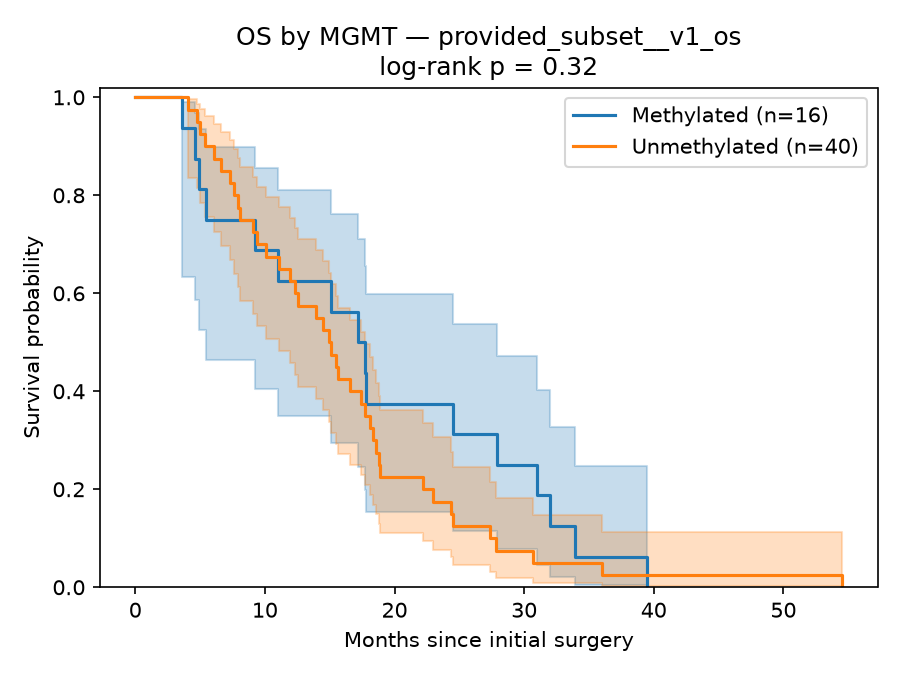

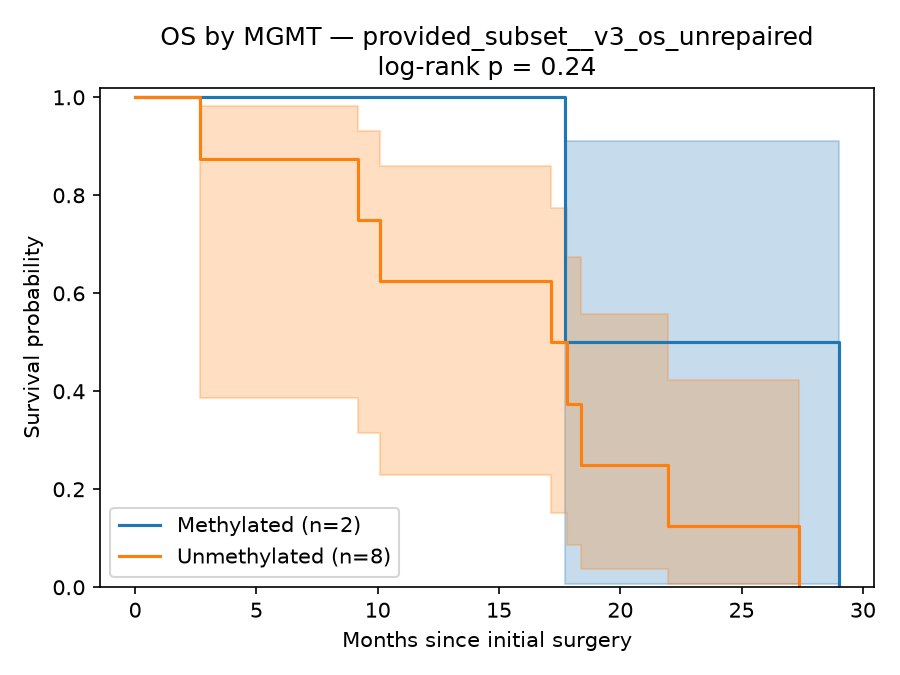

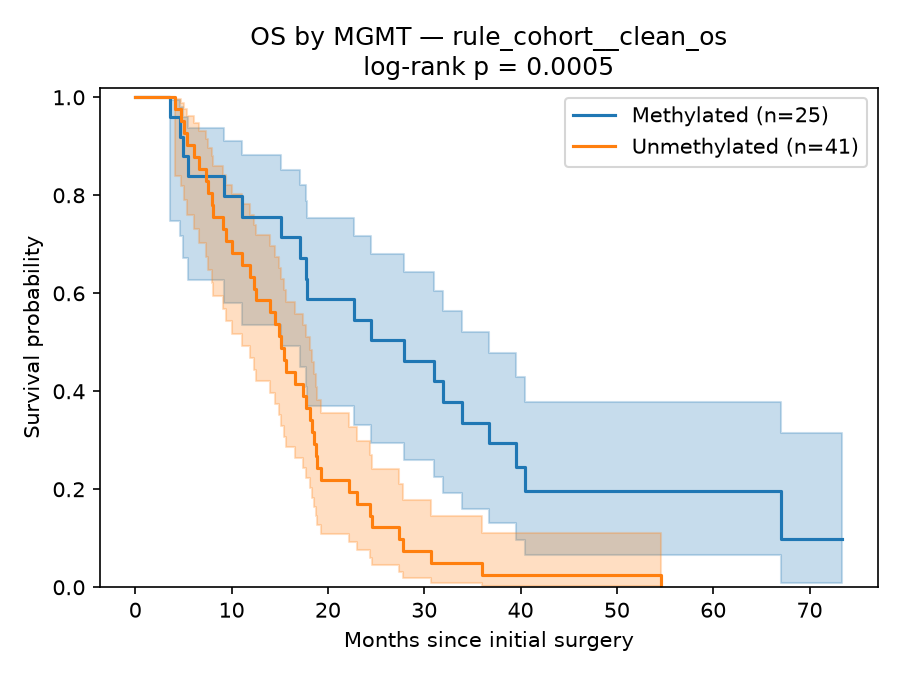

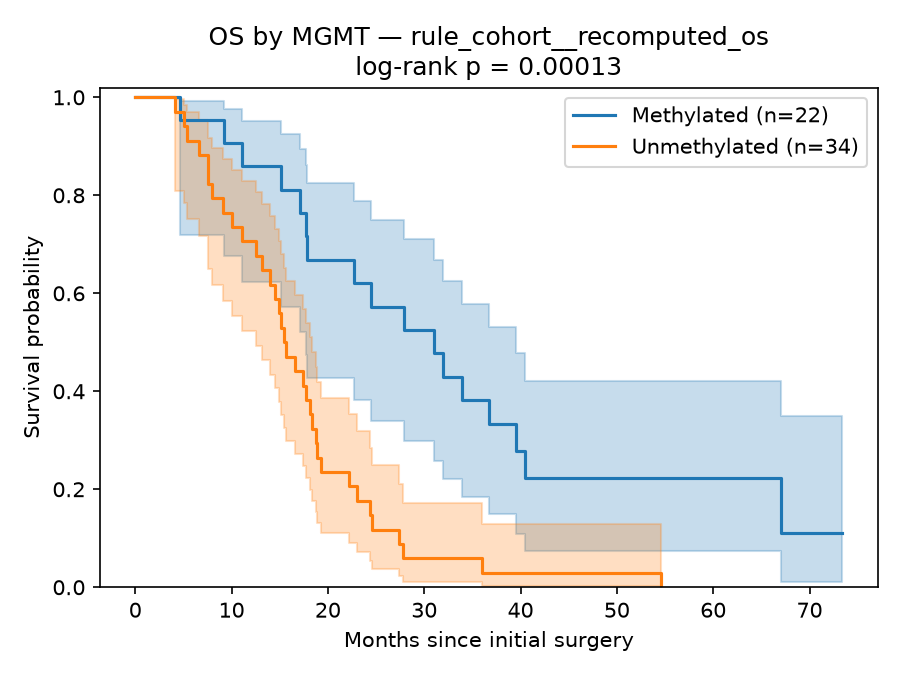

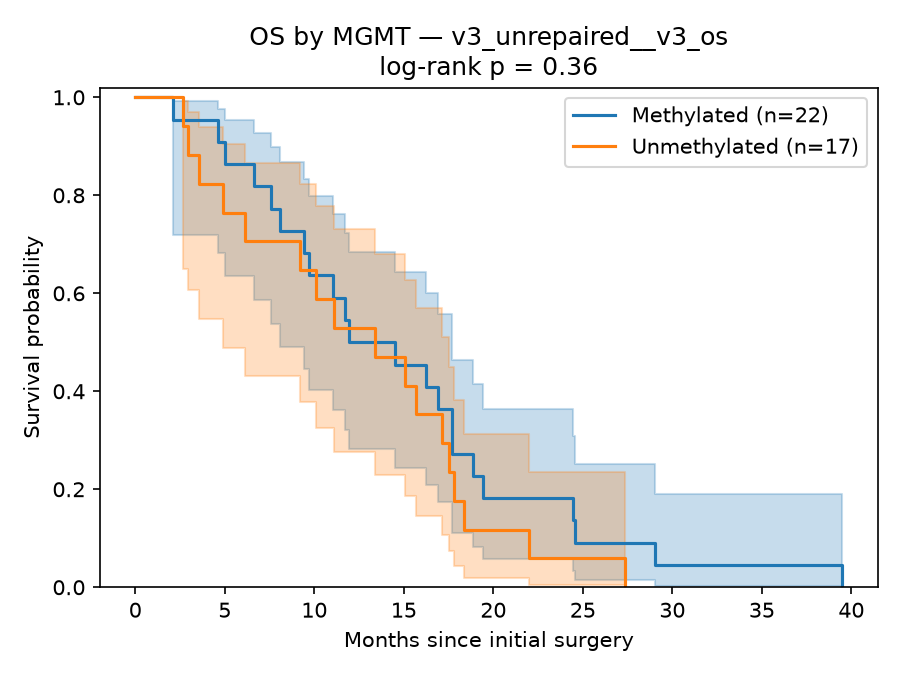

In [4]:
from IPython.display import Image, display
from ucsd_pfs.config import FIGURES_DIR

for f in sorted(FIGURES_DIR.glob("fig2_*.png")):
    display(Image(filename=f))